# Task 3: Multi-Class Image Classification with a CNN

A convolutional neural network (CNN) built with TensorFlow/Keras classifies the handwritten digits of MNIST into ten classes. The same network is trained twice, once on the original images and once with data augmentation (random rotation, shift and zoom), to see how augmentation changes overfitting. The notebook plots the training and validation accuracy of both runs and evaluates both models on the 10,000 test images.

In [1]:
import json
import logging
import os
import sys
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow start-up messages

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from keras import layers
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator, NullLocator, PercentFormatter
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

logging.basicConfig(level=logging.WARNING, format="%(levelname)s | %(message)s", stream=sys.stdout, force=True)
log = logging.getLogger("task3")
log.setLevel(logging.INFO)
tf.config.experimental.enable_op_determinism()  # repeatable results for a given seed

SEED = 42
EPOCHS, BATCH_SIZE, VAL_SIZE = 20, 128, 0.1
CLASS_NAMES = [str(digit) for digit in range(10)]
VARIANTS = {"baseline": "CNN without augmentation", "augmented": "CNN with augmentation"}
DATA_PATH = Path("data/mnist.npz")
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(exist_ok=True)

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.18 | TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.5.3 | scikit-learn 1.9.1


In [2]:
# Plot style: light surface, thin marks, quiet grid
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "legend.fontsize": 9,
})


def save_figure(fig, name):
    """Save a figure to figures/ at print resolution, without software metadata."""
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", metadata={"Software": None})


def show_digit(ax, image):
    """Draw one 28 x 28 image as dark ink on a light background."""
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=255)
    ax.axis("off")


def label_line_ends(ax, items, min_gap=11):
    """Name each line at its last point; labels closer than min_gap points are pushed apart."""
    to_points = 72 / ax.figure.dpi
    items = sorted(items, key=lambda item: item[2])          # (text, x, y), bottom to top
    ends = [ax.transData.transform((x, y))[1] * to_points for _, x, y in items]
    placed = list(ends)
    for _ in range(len(placed)):
        for i in range(1, len(placed)):
            overlap = min_gap - (placed[i] - placed[i - 1])
            if overlap > 0:
                placed[i - 1] -= overlap / 2
                placed[i] += overlap / 2
    for (text, x, y), end, label_y in zip(items, ends, placed):
        ax.annotate(text, xy=(x, y), xytext=(6, label_y - end), textcoords="offset points",
                    ha="left", va="center", fontsize=9, color=INK_2)

## 1. Load and inspect the data

MNIST holds 70,000 grayscale images of handwritten digits (0 to 9), each 28 × 28 pixels: 60,000 for training and 10,000 for testing. A copy is stored in `data/mnist.npz`; if the file is missing, Keras downloads the data again.

In [3]:
def load_mnist(path: Path):
    """Read the local copy of MNIST; download it through Keras and cache it on first use."""
    if not path.exists():
        (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
        path.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(path, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test)
    with np.load(path) as data:
        return (data["x_train"], data["y_train"]), (data["x_test"], data["y_test"])


(x_pool, y_pool), (x_test, y_test) = load_mnist(DATA_PATH)
print(f"Training images: {x_pool.shape}, test images: {x_test.shape}, "
      f"{x_pool.dtype} pixel values from {x_pool.min()} to {x_pool.max()}")

Training images: (60000, 28, 28), test images: (10000, 28, 28), uint8 pixel values from 0 to 255


In [4]:
counts = pd.DataFrame({"training images": np.bincount(y_pool), "test images": np.bincount(y_test)},
                      index=pd.Index(CLASS_NAMES, name="digit"))
counts["share of training (%)"] = (100 * counts["training images"] / len(y_pool)).round(1)
counts

,training images,test images,share of training (%)
digit,,,
0,5923,980,9.9
1,6742,1135,11.2
2,5958,1032,9.9
3,6131,1010,10.2
4,5842,982,9.7
5,5421,892,9.0
6,5918,958,9.9
7,6265,1028,10.4
8,5851,974,9.8


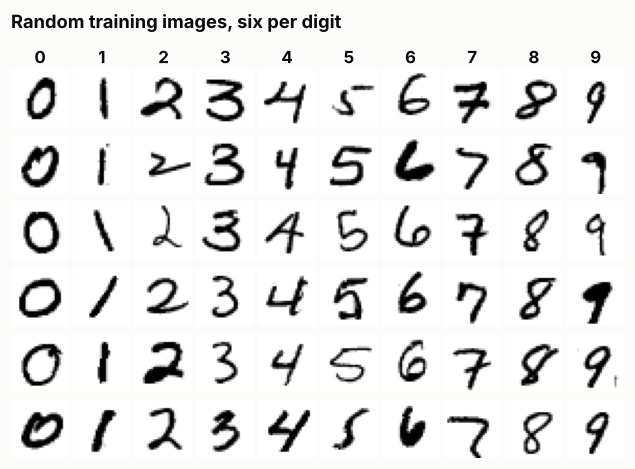

In [5]:
rng = np.random.default_rng(SEED)
per_class = 6
fig, axes = plt.subplots(per_class, 10, figsize=(7.2, 4.7))
for digit in range(10):
    picks = rng.choice(np.flatnonzero(y_pool == digit), per_class, replace=False)
    for row, index in enumerate(picks):
        show_digit(axes[row, digit], x_pool[index])
    axes[0, digit].set_title(CLASS_NAMES[digit], loc="center", fontsize=11, pad=4)
fig.suptitle("Random training images, six per digit", x=0.125, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.subplots_adjust(wspace=0.06, hspace=0.06, top=0.87)
save_figure(fig, "01_sample_digits.png")
plt.show()

The classes are close to balanced, from 5,421 training images of the digit 5 (9.0%) to 6,742 of the digit 1 (11.2%), so accuracy is a fair summary of performance here. The digits are centred in the frame with an empty border of about four pixels, which leaves room for small shifts and rotations.

## 2. Training, validation and test sets

In [6]:
def to_model_input(images: np.ndarray) -> np.ndarray:
    """(n, 28, 28) uint8 -> (n, 28, 28, 1) float32. Pixel values stay 0-255; the model rescales them."""
    return images[..., None].astype("float32")


def split_data(x_pool, y_pool, x_test, y_test, val_size: float, seed: int) -> dict:
    """Hold out a stratified validation set; the official test set is kept for the final evaluation."""
    x_train, x_val, y_train, y_val = train_test_split(
        x_pool, y_pool, test_size=val_size, stratify=y_pool, random_state=seed
    )
    return {
        "train": (to_model_input(x_train), y_train),
        "validation": (to_model_input(x_val), y_val),
        "test": (to_model_input(x_test), y_test),
    }


splits = split_data(x_pool, y_pool, x_test, y_test, VAL_SIZE, SEED)
for name, (x, y) in splits.items():
    print(f"{name:<10} {len(y):>6,} images, model input shape {x.shape[1:]}")

train      54,000 images, model input shape (28, 28, 1)
validation  6,000 images, model input shape (28, 28, 1)
test       10,000 images, model input shape (28, 28, 1)


A stratified 10% of the training images (6,000) is held out for validation. It is used to follow overfitting during training and to choose the epoch whose weights are kept. The 10,000 test images are used once, for the final evaluation. Pixel values stay at 0–255 because the first layer of the network rescales them, so the saved model can classify raw images.

## 3. Data augmentation

With augmentation, the model sees a slightly different version of each training image in every epoch: rotated by up to ±10°, shifted by up to ±10% of the image size (about 3 pixels) in each direction and zoomed in or out by up to 10%. Images are not flipped, because a mirrored 2, 3 or 7 is no longer a valid digit. Augmentation is applied to training batches only; validation and test images are never changed.

In [7]:
def build_augmentation(seed: int) -> keras.Sequential:
    """Random rotation, shift and zoom for training batches.

    No flips: a mirrored digit is no longer the same symbol.
    """
    fill = {"fill_mode": "constant", "fill_value": 0.0}  # pixels moved in from outside the image are black
    return keras.Sequential([
        layers.RandomRotation(10 / 360, seed=seed, **fill),     # up to ±10 degrees
        layers.RandomTranslation(0.1, 0.1, seed=seed, **fill),  # up to ±10% of the image size (about 3 pixels)
        layers.RandomZoom(0.1, seed=seed, **fill),              # up to ±10%
    ], name="augmentation")

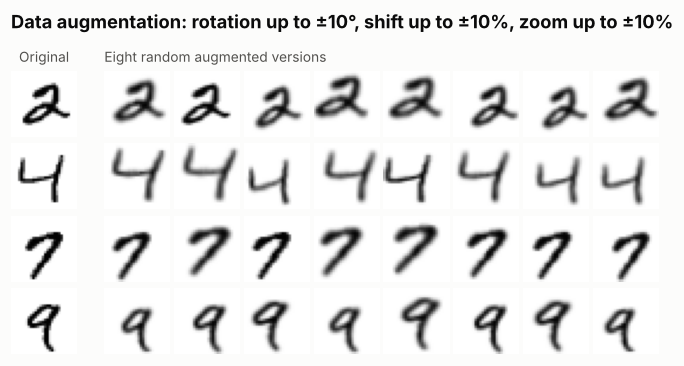

In [8]:
augment_demo = build_augmentation(SEED)  # a separate copy for this figure; each model builds its own
examples = [np.flatnonzero(y_pool == digit)[0] for digit in (2, 4, 7, 9)]
versions = 8
batch = np.repeat(to_model_input(x_pool[examples]), versions, axis=0)
augmented = keras.ops.convert_to_numpy(augment_demo(batch, training=True))
augmented = augmented.reshape(len(examples), versions, 28, 28)

fig, axes = plt.subplots(len(examples), versions + 2, figsize=(7.6, 3.6),
                         gridspec_kw={"width_ratios": [1, 0.3] + [1] * versions})
for row, index in enumerate(examples):
    show_digit(axes[row, 0], x_pool[index])
    axes[row, 1].axis("off")
    for col in range(versions):
        show_digit(axes[row, col + 2], augmented[row, col])
axes[0, 0].set_title("Original", loc="center", fontsize=9, fontweight="normal", color=INK_2, pad=6)
axes[0, 2].set_title("Eight random augmented versions", loc="left", fontsize=9, fontweight="normal",
                     color=INK_2, pad=6)
fig.suptitle("Data augmentation: rotation up to ±10°, shift up to ±10%, zoom up to ±10%",
             x=0.125, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.subplots_adjust(wspace=0.06, hspace=0.06, top=0.83)
save_figure(fig, "02_augmentation_examples.png")
plt.show()

## 4. CNN architecture

In [9]:
def build_cnn(name: str, augmentation: keras.Sequential | None = None) -> keras.Model:
    """Three convolutional layers, two max-pooling layers and two fully connected layers."""
    inputs = keras.Input(shape=(28, 28, 1), name="image")
    x = inputs if augmentation is None else augmentation(inputs)    # active during training only
    x = layers.Rescaling(1 / 255, name="rescale")(x)                 # pixel values 0-255 -> 0-1
    x = layers.Conv2D(32, 3, activation="relu", name="conv1")(x)     # -> 26 x 26 x 32
    x = layers.MaxPooling2D(2, name="pool1")(x)                      # -> 13 x 13 x 32
    x = layers.Conv2D(64, 3, activation="relu", name="conv2")(x)     # -> 11 x 11 x 64
    x = layers.MaxPooling2D(2, name="pool2")(x)                      # -> 5 x 5 x 64
    x = layers.Conv2D(128, 3, activation="relu", name="conv3")(x)    # -> 3 x 3 x 128
    x = layers.Flatten(name="flatten")(x)                            # -> 1,152 values
    x = layers.Dense(128, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.5, name="dropout")(x)
    outputs = layers.Dense(10, activation="softmax", name="output")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


build_cnn("cnn_baseline").summary(print_fn=print)

Model: "cnn_baseline"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼───────────────────

Three 3 × 3 convolutional layers with 32, 64 and 128 filters pick up local patterns, from short strokes in the first layer to larger parts of a digit in the third. Two 2 × 2 max-pooling layers halve the feature maps after the first and second convolutions. This cuts computation and makes the features less sensitive to the exact position of a stroke. The fully connected part has a hidden layer of 128 units with dropout (rate 0.5) and a 10-unit softmax output that gives one probability per digit. The network has 241,546 trainable parameters, 61% of them in the first fully connected layer. The augmented model is the same network with the augmentation block in front; that block has no weights and is switched off at prediction time.

## 5. Training

Both models are trained for 20 epochs with the Adam optimizer (learning rate 0.001), batches of 128 images and sparse categorical cross-entropy loss. They start from the same random weights and see the batches in the same order, so augmentation is the only difference between them. After every epoch the model is scored on the validation set, and the weights from the epoch with the lowest validation loss are kept.

In [10]:
class EpochLogger(keras.callbacks.Callback):
    """Write one log line per epoch."""

    def __init__(self, label: str):
        super().__init__()
        self.label = label

    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        log.info(f"{self.label} | epoch {epoch + 1:>2}/{self.params['epochs']} | "
                 f"train loss {logs['loss']:.4f}, acc {logs['accuracy']:.4f} | "
                 f"val loss {logs['val_loss']:.4f}, acc {logs['val_accuracy']:.4f} | "
                 f"{time.perf_counter() - self.started:.0f} s")


def train_variant(key: str, splits: dict, epochs: int, batch_size: int, models_dir: Path, seed: int):
    """Train one model, then reload the weights of its epoch with the lowest validation loss."""
    keras.utils.set_random_seed(seed)  # both models start from the same weights and batch order
    augmentation = build_augmentation(seed) if key == "augmented" else None
    model = build_cnn(f"cnn_{key}", augmentation)
    (x_train, y_train), (x_val, y_val) = splits["train"], splits["validation"]
    path = Path(models_dir) / f"cnn_{key}.keras"
    path.parent.mkdir(parents=True, exist_ok=True)
    log.info(f"Training {VARIANTS[key]}: {model.count_params():,} parameters, "
             f"{epochs} epochs, batch size {batch_size}")
    started = time.perf_counter()
    fit = model.fit(
        x_train, y_train, validation_data=(x_val, y_val), epochs=epochs, batch_size=batch_size,
        shuffle=True, verbose=0,
        callbacks=[keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True),
                   EpochLogger(VARIANTS[key])],
    )
    seconds = time.perf_counter() - started
    history = pd.DataFrame(fit.history)[["loss", "accuracy", "val_loss", "val_accuracy"]]
    history.insert(0, "epoch", np.arange(1, len(history) + 1))
    return keras.models.load_model(path), history, seconds


models, histories, train_seconds = {}, {}, {}
for key in VARIANTS:
    models[key], histories[key], train_seconds[key] = train_variant(key, splits, EPOCHS, BATCH_SIZE, MODEL_DIR, SEED)

INFO | Training CNN without augmentation: 241,546 parameters, 20 epochs, batch size 128


INFO | CNN without augmentation | epoch  1/20 | train loss 0.2812, acc 0.9138 | val loss 0.0705, acc 0.9797 | 14 s


INFO | CNN without augmentation | epoch  2/20 | train loss 0.0766, acc 0.9771 | val loss 0.0636, acc 0.9830 | 21 s


INFO | CNN without augmentation | epoch  3/20 | train loss 0.0538, acc 0.9845 | val loss 0.0507, acc 0.9862 | 12 s


INFO | CNN without augmentation | epoch  4/20 | train loss 0.0435, acc 0.9869 | val loss 0.0478, acc 0.9865 | 21 s


INFO | CNN without augmentation | epoch  5/20 | train loss 0.0340, acc 0.9901 | val loss 0.0479, acc 0.9863 | 12 s


... (32 outputs left out)

INFO | CNN with augmentation | epoch 17/20 | train loss 0.0389, acc 0.9890 | val loss 0.0406, acc 0.9893 | 14 s


INFO | CNN with augmentation | epoch 18/20 | train loss 0.0389, acc 0.9886 | val loss 0.0346, acc 0.9918 | 14 s


INFO | CNN with augmentation | epoch 19/20 | train loss 0.0358, acc 0.9894 | val loss 0.0263, acc 0.9927 | 14 s


INFO | CNN with augmentation | epoch 20/20 | train loss 0.0340, acc 0.9894 | val loss 0.0355, acc 0.9925 | 21 s


## 6. Training and validation curves

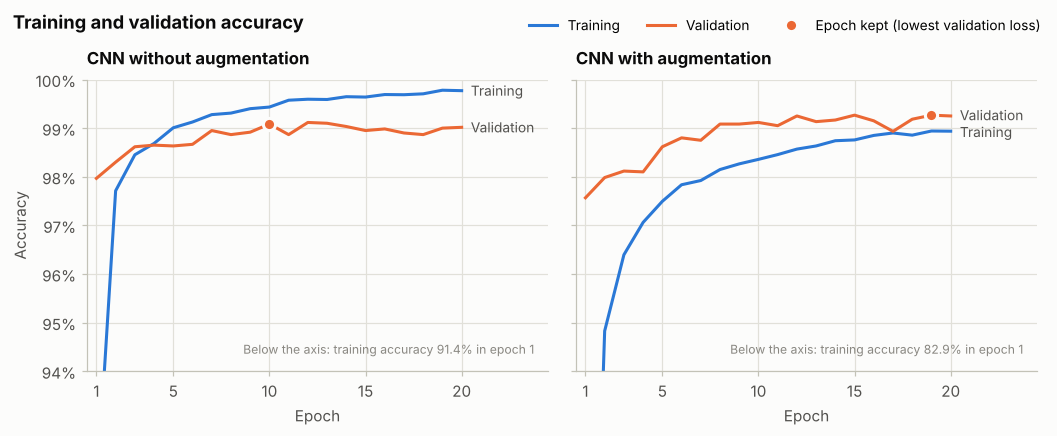

In [11]:
def plot_training_curves(train_col, val_col, y_label):
    """Training vs validation curves, one panel per model, with the kept epoch marked."""
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
    for ax, key in zip(axes, VARIANTS):
        h = histories[key]
        best = int(h["val_loss"].idxmin())
        ax.plot(h["epoch"], h[train_col], color=BLUE, linewidth=2)
        ax.plot(h["epoch"], h[val_col], color=ORANGE, linewidth=2)
        ax.plot(h["epoch"][best], h[val_col][best], "o", ms=8, color=ORANGE, mec=SURFACE, mew=2, zorder=3)
        ax.set_title(VARIANTS[key], fontsize=11)
        ax.set_xlabel("Epoch")
        ax.set_xlim(0.5, len(h) + 4.5)                      # room for the line labels
        ax.set_xticks([1] + list(range(5, len(h) + 1, 5)))
    axes[0].set_ylabel(y_label)
    return fig, axes


def finish_curves(fig, axes, train_col, val_col, title):
    """Title, legend and layout; then name both lines at their last epoch."""
    legend = [Line2D([], [], color=BLUE, linewidth=2, label="Training"),
              Line2D([], [], color=ORANGE, linewidth=2, label="Validation"),
              Line2D([], [], marker="o", ms=8, color=ORANGE, mec=SURFACE, mew=2, linestyle="none",
                     label="Epoch kept (lowest validation loss)")]
    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.14, top=0.82, wspace=0.06)
    fig.suptitle(title, x=0.01, y=0.98, ha="left", fontsize=12, fontweight="bold", color=INK)
    fig.legend(handles=legend, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=3)
    for ax, key in zip(axes, VARIANTS):
        h = histories[key]
        label_line_ends(ax, [("Training", len(h), h[train_col].iloc[-1]),
                             ("Validation", len(h), h[val_col].iloc[-1])])


fig, axes = plot_training_curves("accuracy", "val_accuracy", "Accuracy")
# The axis starts at the lowest whole percent reached from epoch 2 on; lower epoch-1 values are noted
later = [h.iloc[1:] if len(h) > 1 else h for h in histories.values()]
floor = np.floor(min(h[["accuracy", "val_accuracy"]].min().min() for h in later) * 100) / 100
axes[0].set_ylim(floor, 1.0)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for ax, key in zip(axes, VARIANTS):
    below = histories[key].query("accuracy < @floor")
    if len(below):
        values = ", ".join(f"{acc:.1%} in epoch {epoch}" for epoch, acc in zip(below["epoch"], below["accuracy"]))
        ax.text(0.97, 0.05, f"Below the axis: training accuracy {values}", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8, color=MUTED)
finish_curves(fig, axes, "accuracy", "val_accuracy", "Training and validation accuracy")
save_figure(fig, "03_accuracy_curves.png")
plt.show()

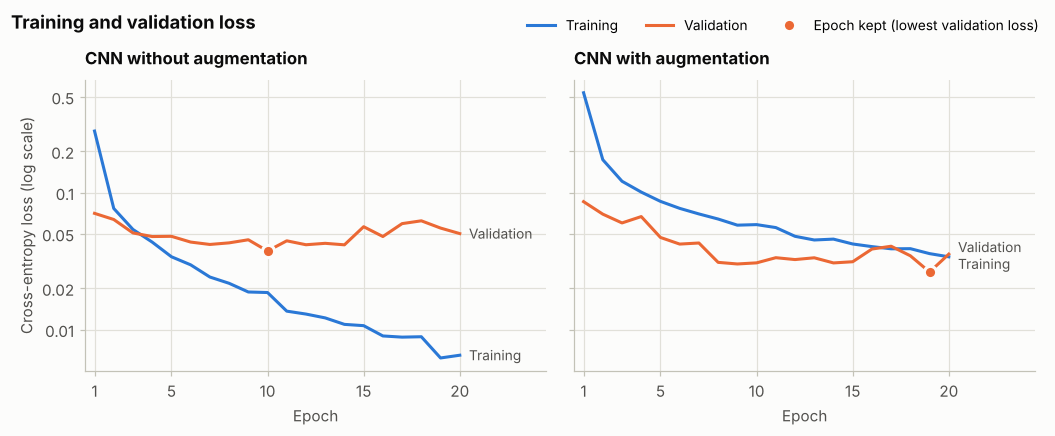

In [12]:
fig, axes = plot_training_curves("loss", "val_loss", "Cross-entropy loss (log scale)")
axes[0].set_yscale("log")
ticks = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
axes[0].set_yticks(ticks, [f"{tick:g}" for tick in ticks])
axes[0].yaxis.set_minor_locator(NullLocator())
finish_curves(fig, axes, "loss", "val_loss", "Training and validation loss")
save_figure(fig, "04_loss_curves.png")
plt.show()

**Reading the curves.** Without augmentation, training accuracy keeps climbing (99.77% in the last epoch) while validation accuracy stays between 98.9% and 99.1% from epoch 7 on. Validation loss reaches its lowest value at epoch 10 (0.0374) and then drifts up to 0.0502 by epoch 20: the network has started to fit details of its training images that do not carry over to new ones. With augmentation, training accuracy stays below validation accuracy in every epoch, because each training batch is a randomly altered, harder version of the images and dropout is active during training only. Validation loss keeps improving until epoch 19 (0.0263). It moves up and down from one epoch to the next, which is why the epoch with the lowest validation loss is kept instead of the last one.

## 7. Evaluation on the test set

Each model is scored with its kept weights, with dropout and augmentation switched off, on the training, validation and test images. The gap between training and validation accuracy measures overfitting: the larger it is, the more the model has learned details that hold only for the training images.

In [13]:
def evaluate(model: keras.Model, x: np.ndarray, y: np.ndarray):
    """Accuracy, cross-entropy loss, macro F1 and error count, with augmentation and dropout off."""
    probs = model.predict(x, batch_size=1000, verbose=0)
    pred = probs.argmax(axis=1)
    loss = -np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1.0)).mean()
    scores = {
        "accuracy": round(float((pred == y).mean()), 4),
        "loss": round(float(loss), 4),
        "macro_f1": round(float(f1_score(y, pred, average="macro")), 4),
        "errors": int((pred != y).sum()),
    }
    return scores, probs


def summarize_variant(key: str, model: keras.Model, history: pd.DataFrame, seconds: float, splits: dict):
    """Scores on every split and one row for the comparison table."""
    scores, probs = {}, {}
    for split, (x, y) in splits.items():
        scores[split], probs[split] = evaluate(model, x, y)
    best_epoch = int(history["val_loss"].idxmin()) + 1
    summary = {"label": VARIANTS[key], "parameters": model.count_params(), "best_epoch": best_epoch,
               "train_time_s": round(seconds), **scores}
    row = {
        "model": VARIANTS[key],
        "parameters": model.count_params(),
        "epochs": len(history),
        "best_epoch": best_epoch,
        "train_accuracy": scores["train"]["accuracy"],
        "val_accuracy": scores["validation"]["accuracy"],
        "train_val_gap": round(scores["train"]["accuracy"] - scores["validation"]["accuracy"], 4),
        "min_val_loss": round(float(history["val_loss"].min()), 4),
        "final_val_loss": round(float(history["val_loss"].iloc[-1]), 4),
        "test_accuracy": scores["test"]["accuracy"],
        "test_loss": scores["test"]["loss"],
        "test_macro_f1": scores["test"]["macro_f1"],
        "test_errors": scores["test"]["errors"],
        "train_time_s": round(seconds),
    }
    log.info(f"{VARIANTS[key]:<24} | best epoch {best_epoch:>2} | train acc {row['train_accuracy']:.4f} | "
             f"val acc {row['val_accuracy']:.4f} | test acc {row['test_accuracy']:.4f} | "
             f"test errors {row['test_errors']} of {len(splits['test'][1]):,} | {row['train_time_s']} s")
    return summary, row, probs["test"]


summaries, rows, test_probs = {}, [], {}
for key in VARIANTS:
    summaries[key], row, test_probs[key] = summarize_variant(key, models[key], histories[key], train_seconds[key], splits)
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("model").drop(columns="train_time_s")
comparison.astype(object).T  # object type keeps whole numbers as integers

INFO | CNN without augmentation | best epoch 10 | train acc 0.9981 | val acc 0.9908 | test acc 0.9931 | test errors 69 of 10,000 | 338 s


INFO | CNN with augmentation    | best epoch 19 | train acc 0.9947 | val acc 0.9927 | test acc 0.9937 | test errors 63 of 10,000 | 334 s


model,CNN without augmentation,CNN with augmentation
parameters,241546,241546
epochs,20,20
best_epoch,10,19
train_accuracy,0.9981,0.9947
val_accuracy,0.9908,0.9927
train_val_gap,0.0073,0.002
min_val_loss,0.0374,0.0263
final_val_loss,0.0502,0.0355
test_accuracy,0.9931,0.9937
test_loss,0.0261,0.0212


Both models classify more than 99.3% of the test images correctly (99.31% without augmentation, 99.37% with it), so on MNIST the accuracy difference is small: 69 errors against 63. Augmentation shows its effect on overfitting. The gap between training and validation accuracy falls from 0.73 to 0.20 percentage points, the lowest validation loss from 0.0374 to 0.0263 and the test loss from 0.0261 to 0.0212.

## 8. Errors of the final model

The final model is the one with the lower validation loss; the test set plays no part in the choice.

In [14]:
final = min(summaries, key=lambda key: summaries[key]["validation"]["loss"])  # chosen on validation data
test_pred = test_probs[final].argmax(axis=1)
print(f"Final model: {VARIANTS[final]} | {summaries[final]['test']['errors']} errors "
      f"on {len(y_test):,} test images")
report = classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
report.pop("accuracy")
pd.DataFrame(report).T.round(4).astype({"support": int}).rename_axis("class")

Final model: CNN with augmentation | 63 errors on 10,000 test images


,precision,recall,f1-score,support
class,,,,
0,0.9949,0.9959,0.9954,980
1,0.9956,0.9947,0.9952,1135
2,0.9971,0.9942,0.9956,1032
3,0.9970,0.9911,0.9940,1010
4,0.9939,0.9980,0.9959,982
5,0.9823,0.9955,0.9889,892
6,0.9937,0.9937,0.9937,958
7,0.9922,0.9951,0.9937,1028
8,0.9938,0.9928,0.9933,974


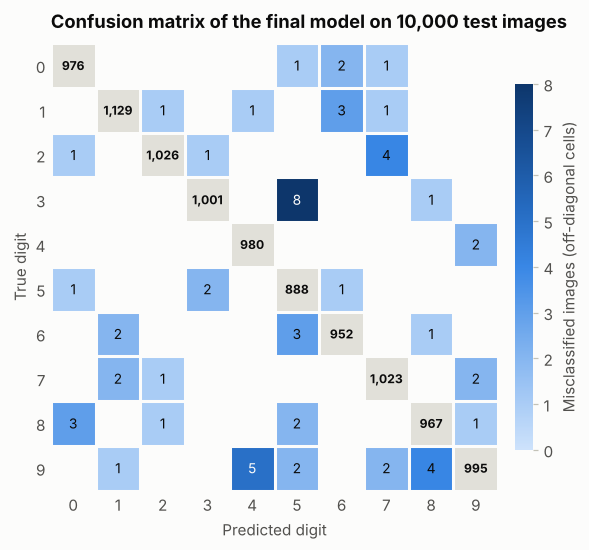

In [15]:
cm = confusion_matrix(y_test, test_pred)
errors = cm.copy()
np.fill_diagonal(errors, 0)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
image = ax.imshow(np.ma.masked_equal(errors, 0), cmap=SEQ_BLUE, vmin=0, vmax=errors.max())
for i in range(10):
    ax.add_patch(Rectangle((i - 0.5, i - 0.5), 1, 1, facecolor=GRID, edgecolor="none", zorder=0.2))
    for j in range(10):
        if cm[i, j] == 0:
            continue
        on_dark = i != j and errors[i, j] > 0.55 * errors.max()
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=8 if i == j else 9,
                color=SURFACE if on_dark else INK, fontweight="bold" if i == j else "normal")
ax.set_xticks(range(10), CLASS_NAMES)
ax.set_yticks(range(10), CLASS_NAMES)
ax.set_xticks(np.arange(-0.5, 10), minor=True)
ax.set_yticks(np.arange(-0.5, 10), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
ax.set_title(f"Confusion matrix of the final model on {len(y_test):,} test images")
bar = fig.colorbar(image, ax=ax, shrink=0.8, pad=0.03)
bar.set_label("Misclassified images (off-diagonal cells)", color=INK_2)
bar.ax.yaxis.set_major_locator(MaxNLocator(integer=True))
bar.outline.set_visible(False)
bar.ax.tick_params(color=AXIS, labelcolor=INK_2)
save_figure(fig, "05_confusion_matrix.png")
plt.show()

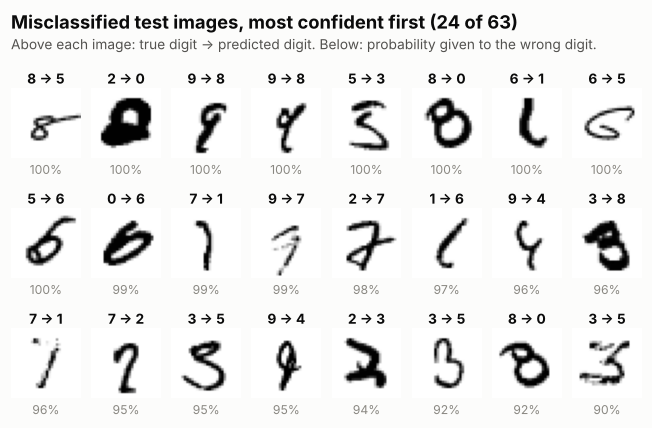

In [16]:
confidence = test_probs[final].max(axis=1)
wrong = np.flatnonzero(test_pred != y_test)
wrong = wrong[np.argsort(-confidence[wrong], kind="stable")]  # most confident mistakes first
shown = wrong[:24]

fig, axes = plt.subplots(3, 8, figsize=(7.4, 4.1))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, shown):
    show_digit(ax, x_test[index])
    ax.set_title(f"{y_test[index]} → {test_pred[index]}", loc="center", fontsize=9, color=INK, pad=3)
    ax.text(0.5, -0.06, f"{confidence[index]:.0%}", transform=ax.transAxes,
            ha="center", va="top", fontsize=8, color=MUTED)
fig.suptitle(f"Misclassified test images, most confident first ({len(shown)} of {len(wrong)})",
             x=0.125, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.text(0.125, 0.895, "Above each image: true digit → predicted digit. Below: probability given to the wrong digit.",
         fontsize=9, color=INK_2)
fig.subplots_adjust(wspace=0.15, hspace=0.5, top=0.82)
save_figure(fig, "06_misclassified_digits.png")
plt.show()

The final model gets 63 of the 10,000 test images wrong. The largest single confusion is a 3 read as a 5 (8 images), followed by a 9 read as a 4 (5 images). Recall is lowest for the digit 9 (98.61%) and precision lowest for the digit 5 (98.23%); half of the 16 images wrongly predicted as 5 are 3s. Many of the misclassified digits are written in unusual ways, with very thick strokes, open loops or strong slants.

## 9. Using the saved model

In [17]:
# Reload the final model and classify five test images given as raw 0-255 pixel values
reloaded = keras.models.load_model(MODEL_DIR / f"cnn_{final}.keras")
probs = reloaded.predict(to_model_input(x_test[:5]), verbose=0)
pd.DataFrame({"true digit": y_test[:5], "predicted digit": probs.argmax(axis=1),
              "confidence (%)": (100 * probs.max(axis=1)).round(2)})

,true digit,predicted digit,confidence (%)
0,7,7,100.0
1,2,2,100.0
2,1,1,100.0
3,0,0,100.0
4,4,4,100.0


The saved file holds the whole network, including the rescaling layer, so it takes raw images of shape (n, 28, 28, 1) and needs no separate preprocessing step.